# Evaluación 2 — Big Data, Opción C
**Colab + PySpark + Databricks + Supabase/PostgreSQL.** Ejecute las celdas en orden; adjunte capturas reales. Los datos son de NYC TLC.

In [ ]:

%pip install -q pyspark==4.0.1 pandas matplotlib



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 434.2/434.2 MB 1.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.0/203.0 kB 15.0 MB/s eta 0:00:00


In [ ]:
import os, json, pathlib, urllib.request
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.stat import Summarizer
spark=SparkSession.builder.appName("BigDataOpcionC").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
print("Spark",spark.version)


Spark 4.0.1


## 1. Ingesta batch. Persistencia: en Colab `/content` es temporal; copie las salidas a Drive o almacenamiento persistente autorizado. Databricks requiere adaptar las rutas.

In [ ]:
url="https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
os.makedirs("/content/bigdata/raw",exist_ok=True)
rawfile="/content/bigdata/raw/yellow_tripdata_2024-01.parquet"
if not os.path.exists(rawfile): urllib.request.urlretrieve(url, rawfile)
raw=spark.read.parquet(rawfile)
raw.printSchema()
print("filas origen:",raw.count())


root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)

filas origen: 2964624


## 2. ETL y Parquet particionado

In [ ]:
df=(raw.withColumn("pickup",F.col("tpep_pickup_datetime"))
 .withColumn("duration_min",(F.unix_timestamp("tpep_dropoff_datetime")-F.unix_timestamp("tpep_pickup_datetime"))/60.0)
 .withColumn("hour",F.hour("pickup"))
 .withColumn("weekday",F.dayofweek("pickup"))
 .withColumn("year",F.year("pickup"))
 .withColumn("month",F.month("pickup")))
df=df.filter((F.col("year")==2024)&(F.col("month")==1)&F.col("duration_min").between(1,180)&F.col("trip_distance").between(0.01,100)&F.col("fare_amount").between(0.01,500))
print("válidas:",df.count())
silver="/content/bigdata/silver"
df.write.mode("overwrite").partitionBy("year","month").parquet(silver,compression="snappy")


válidas: 2858939


## 3. EDA con Spark SQL

In [ ]:
df.createOrReplaceTempView("trips")
summary=spark.sql("SELECT COUNT(*) viajes, ROUND(AVG(duration_min),2) duracion_media, ROUND(AVG(trip_distance),2) distancia_media, ROUND(AVG(fare_amount),2) tarifa_media FROM trips")
summary.show()
hourly=spark.sql("SELECT hour, COUNT(*) trips, ROUND(AVG(duration_min),2) avg_duration_min, ROUND(AVG(fare_amount),2) avg_fare FROM trips GROUP BY hour ORDER BY hour")
hourly.show(24)
hourly.coalesce(1).write.mode("overwrite").parquet("/content/bigdata/gold/hourly")


+-------+--------------+---------------+------------+
| viajes|duracion_media|distancia_media|tarifa_media|
+-------+--------------+---------------+------------+
|2858939|          15.0|            3.3|       18.45|
+-------+--------------+---------------+------------+

+----+------+----------------+--------+
|hour| trips|avg_duration_min|avg_fare|
+----+------+----------------+--------+
|   0| 74843|           13.78|   19.64|
|   1| 50188|           12.75|   17.68|
|   2| 34761|           12.06|   16.58|
|   3| 22771|           12.23|    18.5|
|   4| 15132|            14.1|   23.38|
|   5| 17333|           16.66|   27.46|
|   6| 39227|            15.8|   21.98|
|   7| 80552|           15.04|   18.72|
|   8|113130|           15.21|   17.79|
|   9|125173|           15.16|   17.92|
|  10|134958|           15.27|   18.02|
|  11|146255|           15.14|   17.59|
|  12|159381|           15.14|   17.76|
|  13|164712|           15.53|   18.38|
|  14|177311|           16.49|   19.22|
|  15|183

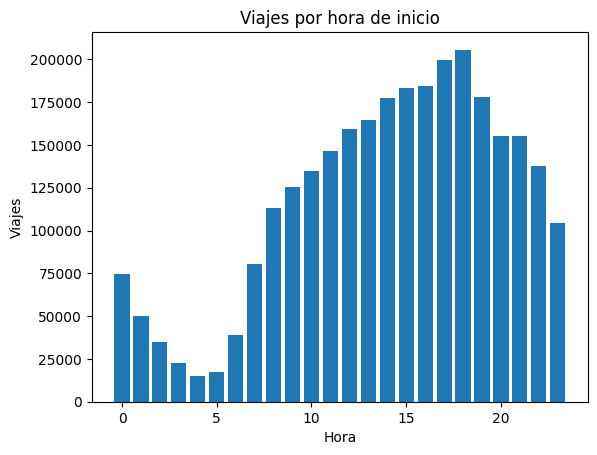

In [ ]:
import matplotlib.pyplot as plt
pdf=hourly.toPandas() # Solo 24 filas agregadas, no todo el dataset
plt.bar(pdf["hour"],pdf["trips"]);plt.xlabel("Hora");plt.ylabel("Viajes");plt.title("Viajes por hora de inicio");plt.show()


## 4. ML: regresión, línea base y métricas reales (no inventadas). Nota: `trip_distance` medida postviaje no sirve como predictor en tiempo real sin una estimación previa.

In [ ]:
features=["trip_distance","passenger_count","hour","weekday","PULocationID"]
model_df=df.select(*features,"duration_min").withColumn("PULocationID",F.col("PULocationID").cast("double"))
train,test=model_df.randomSplit([0.8,0.2],seed=42)
imputer=Imputer(inputCols=features,outputCols=["i_"+v for v in features])
assembler=VectorAssembler(inputCols=["i_"+v for v in features],outputCol="features")
rf=RandomForestRegressor(featuresCol="features",labelCol="duration_min",numTrees=40,maxDepth=8,seed=42)
pipe=Pipeline(stages=[imputer,assembler,rf])
fit=pipe.fit(train);prediction=fit.transform(test).cache()
metrics={m:RegressionEvaluator(labelCol="duration_min",predictionCol="prediction",metricName=m).evaluate(prediction) for m in ["rmse","mae","r2"]}
baseline=train.agg(F.avg("duration_min")).first()[0]
baseline_mae=test.select(F.avg(F.abs(F.col("duration_min")-F.lit(baseline)))).first()[0]
metrics["baseline_mae"]=baseline_mae
metrics["n_train"]=train.count();metrics["n_test"]=test.count()
print(json.dumps(metrics,indent=2))
with open("/content/bigdata/metricas.json","w") as f:json.dump(metrics,f,indent=2)


{
  "rmse": 5.980243157770687,
  "mae": 3.6339716438436005,
  "r2": 0.7433324345565895,
  "baseline_mae": 8.234657156448186,
  "n_train": 2287353,
  "n_test": 571586
}


## 5. Supabase/PostgreSQL y Databricks
1. Crear proyecto y ejecutar `supabase_schema.sql` en SQL Editor.
2. Exportar `hourly` a CSV y cargar **solo sus 24 filas** mediante importación CSV/SQL Editor; no almacene el dataset completo en Postgres gratuito.
3. En Databricks Free/Community, cargar el dataset a un espacio accesible y adaptar rutas para reejecutar el bloque PySpark; guardar pantallazos de ejecución.
4. Agregar resultados reales y enlaces a GitHub.
5. Para cumplir resiliencia, comprobar reejecución leyendo los Parquet persistidos después de un reinicio. Los datos en `/content` se pierden al cerrar Colab.

In [ ]:
hourly.toPandas().to_csv("/content/bigdata/hourly_para_supabase.csv",index=False)
print("CSV creado: /content/bigdata/hourly_para_supabase.csv")


CSV creado: /content/bigdata/hourly_para_supabase.csv
